In [136]:
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.stats import norm
import seaborn as sns

In [3]:
# okay so here is the deal: We need to store patterns in a matrix and then look at their potential for instability

In [39]:
# set up

N = 500 
alpha = .38
P = int(N*alpha)
rng = np.random.default_rng(0)
patterns = rng.choice([-1, 1], size=(N, P))

In [41]:
# create weight matrix
W = np.zeros((N,N))
for i in range(P):
    W_step = np.outer(patterns[:,i], patterns[:,i])
    W = W + W_step

for i in range(N):
    W[i,i] = 0

In [45]:
# now calculate that stuff in the first part of the question
for i in range(P):
    h_vec = W @ patterns[:,i]
    unstable_count = patterns[:,i] * h_vec
    #print("Number of negative is :", sum(unstable_count < 0))

In [51]:
def unstable_bits(N, alpha):
    P = int(N*alpha)
    rng = np.random.default_rng(0)
    patterns = rng.choice([-1, 1], size=(N, P))
    
    # create weight matrix
    W = np.zeros((N,N))
    for i in range(P):
        W_step = np.outer(patterns[:,i], patterns[:,i])
        W = W + W_step
    
    for i in range(N):
        W[i,i] = 0

    # now calculate that stuff in the first part of the question
    total_count = 0
    for i in range(P):
        h_vec = W @ patterns[:,i]
        unstable_vec = patterns[:,i] * h_vec
        total_count += sum(unstable_vec < 0)
        
    return total_count

In [63]:
alpha_list = np.linspace(.02, .62, 31)
unstable_list = [unstable_bits(500, a)/(500*a*500) for a in alpha_list]

In [64]:
unstable_list

[0.0,
 0.0,
 0.0,
 0.0002,
 0.0006,
 0.0018666666666666664,
 0.0028571428571428576,
 0.005675,
 0.008311111111111111,
 0.011940000000000001,
 0.0168,
 0.0204,
 0.02446153846153846,
 0.02807142857142857,
 0.03378666666666666,
 0.0387875,
 0.04157647058823529,
 0.04895555555555555,
 0.04952631578947368,
 0.05452,
 0.06012380952380952,
 0.06720909090909091,
 0.0709304347826087,
 0.07318333333333332,
 0.076952,
 0.08436923076923077,
 0.08617777777777778,
 0.08857857142857142,
 0.09342758620689653,
 0.09787333333333334,
 0.10010967741935484]

In [108]:
z_vals = -1/np.sqrt(alpha_list)
Phi = norm.cdf(z_vals)
Phi

array([7.68729897e-13, 2.86651572e-07, 2.22785453e-05, 2.03476009e-04,
       7.82701129e-04, 1.94620856e-03, 3.76315758e-03, 6.20966533e-03,
       9.21106273e-03, 1.26736593e-02, 1.65031288e-02, 2.06134167e-02,
       2.49301019e-02, 2.93908607e-02, 3.39445774e-02, 3.85499359e-02,
       4.31739105e-02, 4.77903523e-02, 5.23787449e-02, 5.69231490e-02,
       6.14113241e-02, 6.58340080e-02, 7.01843304e-02, 7.44573366e-02,
       7.86496035e-02, 8.27589293e-02, 8.67840833e-02, 9.07246039e-02,
       9.45806363e-02, 9.83528012e-02, 1.02042089e-01])

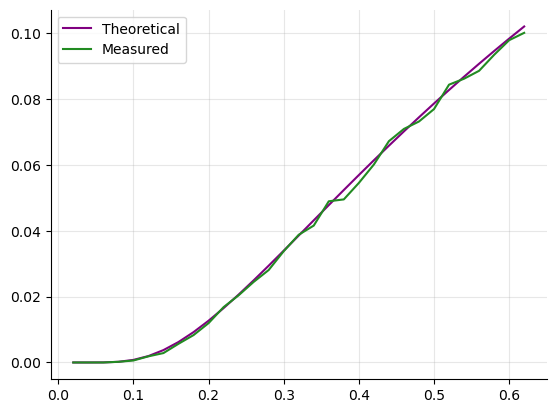

In [163]:
plt.plot(alpha_list, Phi, 
         label = "Theoretical",
         color = "purple")
plt.plot(alpha_list, unstable_list,
         label = "Measured",
         color = "forestgreen")
# plt.title("Number of unstable bits as a function of proportion of patterns stored")
plt.legend()
sns.despine()
plt.grid(alpha = .3)
plt.savefig("unstable_bits", dpi=300, bbox_inches="tight")
plt.show()

In [147]:
# second part of the question: we are testing recall somehow
def recall(N, alpha, seed):
    P = int(N*alpha)
    rng = np.random.default_rng(seed)
    patterns = rng.choice([-1, 1], size=(N, P))
    
    # create weight matrix
    W = np.zeros((N,N))
    for i in range(P):
        W_step = np.outer(patterns[:,i], patterns[:,i])
        W = W + W_step
    
    for i in range(N):
        W[i,i] = 0

    # start from a pattern with 10% of its bits flipped:
    rng = np.random.default_rng(seed)
    pat_start = patterns[:, 0].copy()
    flip_indices = rng.choice(500, size=50, replace=False)
    pat_start[flip_indices] *= -1
    # print(np.sum(pat_start != patterns[:, 0]))
    
    # run an update with a random order until an entire pass through does nothing:
    pat_cur = pat_start
    updates = np.inf
    while updates != 0:
        updates = 0
        flip_order = random.sample(range(500), 500)
        for f in flip_order:
            before = pat_cur[f]
            h_f = np.dot(W[f,:], pat_start)
            pat_cur[f] = 1 if h_f == 0 else np.sign(h_f)

            if pat_cur[f] != before:
                updates += 1


    # measure overlap between original pattern and final value
    m = np.dot(patterns[:,0], pat_cur)/N
    return m

In [149]:
recall_list = np.zeros(len(alpha_list))

for a in range(len(alpha_list)):
    b = [recall(500, alpha_list[a], a) for _ in range(10)]
    recall_list[a] = np.mean(b)

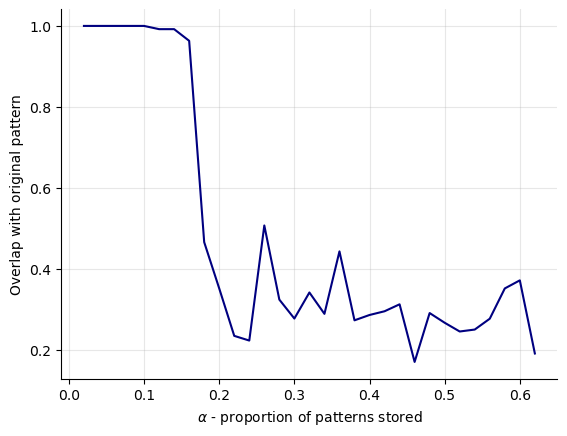

In [161]:
plt.plot(alpha_list, recall_list, "navy")
sns.despine()
plt.grid(alpha = .3)
plt.xlabel(r"$\alpha$ - proportion of patterns stored")
plt.ylabel("Overlap with original pattern")
plt.savefig("overlap", dpi = 300, bbox_inches = "tight")
plt.show()

In [167]:
recall_list

array([1.    , 1.    , 1.    , 1.    , 1.    , 0.992 , 0.992 , 0.9632,
       0.4656, 0.3512, 0.234 , 0.2224, 0.5068, 0.3236, 0.2768, 0.3412,
       0.2884, 0.4428, 0.2724, 0.2856, 0.2948, 0.312 , 0.1696, 0.2904,
       0.2664, 0.2448, 0.2496, 0.2764, 0.3512, 0.3712, 0.1904])